<a href="https://colab.research.google.com/github/maulidyaafriani/PCVK_Genap_2026/blob/main/Week7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 7 – Segmentasi Citra dengan Thresholding
**Praktikum Pengolahan Citra dan Visi Komputer – Jurusan Teknologi Informasi**

Nama: Maulidya Afriani |  NIM: 244107020059


## D1.1 Persiapan: hubungkan Google Drive
Folder gambar: `/content/drive/MyDrive/PCVK/Images/244107020059/`

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

# Folder berisi foto/gambar praktikum
BASE_DIR = '/content/drive/MyDrive/PCVK/Images/244107020059/'

def cari_file(kata_kunci, nama_default):
    # Pakai nama_default kalau ada. Kalau tidak, cari file gambar yang namanya mengandung kata_kunci.
    path = os.path.join(BASE_DIR, nama_default)
    if os.path.exists(path):
        return path
    for f in sorted(os.listdir(BASE_DIR)):
        if kata_kunci.lower() in f.lower() and f.lower().endswith(('.jpg', '.jpeg', '.png')):
            return os.path.join(BASE_DIR, f)
    raise FileNotFoundError(
        f"File '{nama_default}' tidak ditemukan di {BASE_DIR}\n"
        f"Isi folder: {os.listdir(BASE_DIR)}\n"
        f"Ganti nama file di sel ini sesuai isi folder."
    )

# Ubah nama file di sini kalau namanya berbeda di Drive-mu
FILE_SUDOKU = cari_file('sudoku', 'sudoku-original.jpg')
FILE_LENA   = cari_file('lena',   'lena_gs_lc2.jpg')
FILE_KTP    = cari_file('ktp',    'ktp_fulan.jpg')
print('Sudoku :', FILE_SUDOKU)
print('Lena   :', FILE_LENA)
print('KTP    :', FILE_KTP)

Sudoku : /content/drive/MyDrive/PCVK/Images/244107020059/sudoku-original.jpg
Lena   : /content/drive/MyDrive/PCVK/Images/244107020059/lena.jpg
KTP    : /content/drive/MyDrive/PCVK/Images/244107020059/ktp_fulan.jpg


## D1.2 Import library

In [ ]:
#Library yang digunakan
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

## D1.3 Global Threshold secara manual (threshold = 200)

| Jenis | Jika piksel > thresh | Jika piksel ≤ thresh |
|---|---|---|
| BINARY | nilai maksimal | 0 |
| BINARY_INV | 0 | nilai maksimal |
| TRUNC | thresh | nilai asli |
| TOZERO | nilai asli | 0 |
| TOZERO_INV | 0 | nilai asli |

Semua dibuat dengan NumPy (tanpa `cv.threshold`).

gradient.jpg tidak ada di folder -> memakai gradien buatan


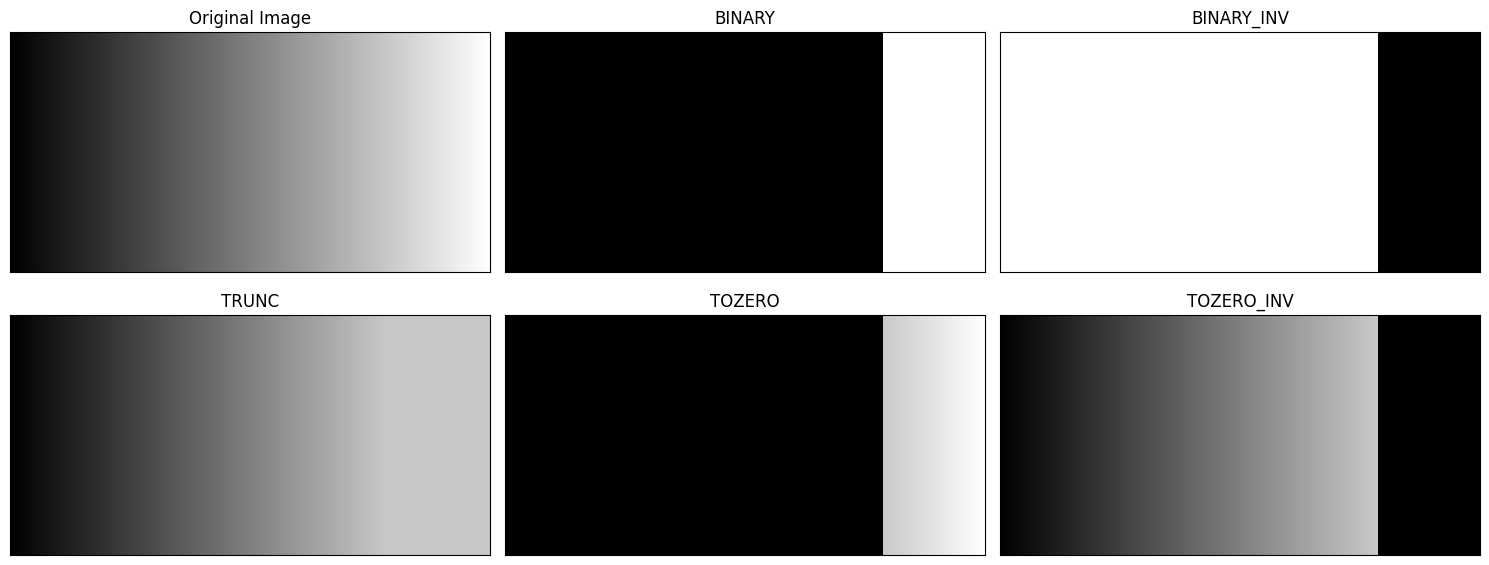

In [ ]:
# Citra gradien (hitam -> putih). Kalau gradient.jpg tidak ada di folder, dibuat gradien buatan.
try:
    FILE_GRADIENT = cari_file('gradient', 'gradient.jpg')
    img_grad = cv.imread(FILE_GRADIENT, 0)
    print('Memakai', FILE_GRADIENT)
except FileNotFoundError:
    print('gradient.jpg tidak ada di folder -> memakai gradien buatan')
    img_grad = np.tile(np.linspace(0, 255, 400).astype(np.uint8), (200, 1))

def thr_binary(src, thresh, maxval=255):
    return np.where(src > thresh, maxval, 0).astype(np.uint8)

def thr_binary_inv(src, thresh, maxval=255):
    return np.where(src > thresh, 0, maxval).astype(np.uint8)

def thr_trunc(src, thresh):
    return np.where(src > thresh, thresh, src).astype(np.uint8)

def thr_tozero(src, thresh):
    return np.where(src > thresh, src, 0).astype(np.uint8)

def thr_tozero_inv(src, thresh):
    return np.where(src > thresh, 0, src).astype(np.uint8)

thresh = 200
maxval = 255

hasil_global = {
    'Original Image': img_grad,
    'BINARY':      thr_binary(img_grad, thresh, maxval),
    'BINARY_INV':  thr_binary_inv(img_grad, thresh, maxval),
    'TRUNC':       thr_trunc(img_grad, thresh),
    'TOZERO':      thr_tozero(img_grad, thresh),
    'TOZERO_INV':  thr_tozero_inv(img_grad, thresh),
}

plt.figure(figsize=(15, 6))
for i, (judul, im) in enumerate(hasil_global.items()):
    plt.subplot(2, 3, i + 1)
    plt.imshow(im, cmap='gray', vmin=0, vmax=255, interpolation='nearest')  # vmin/vmax dikunci agar skala sama
    plt.title(judul)
    plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

## D1.4 Adaptive Threshold manual (Mean & Gaussian)

Ketentuan: **tanpa** `cv.threshold()`, `cv.adaptiveThreshold()`, dan fungsi filter siap pakai. Parameter: global T = 127, jendela 11 × 11, C = 2, σ = 2.

Rumus: `T(x,y) = rata-rata lokal − C`, lalu piksel **putih** jika `I(x,y) > T(x,y)`, selain itu hitam.
- Rata-rata (mean) dihitung dengan *integral image* (`cumsum`).
- Rata-rata Gaussian dihitung dengan kernel Gaussian 1D yang dijumlahkan manual (separable: horizontal lalu vertikal).
- Tepi citra di-*padding* dengan menyalin piksel tepi.

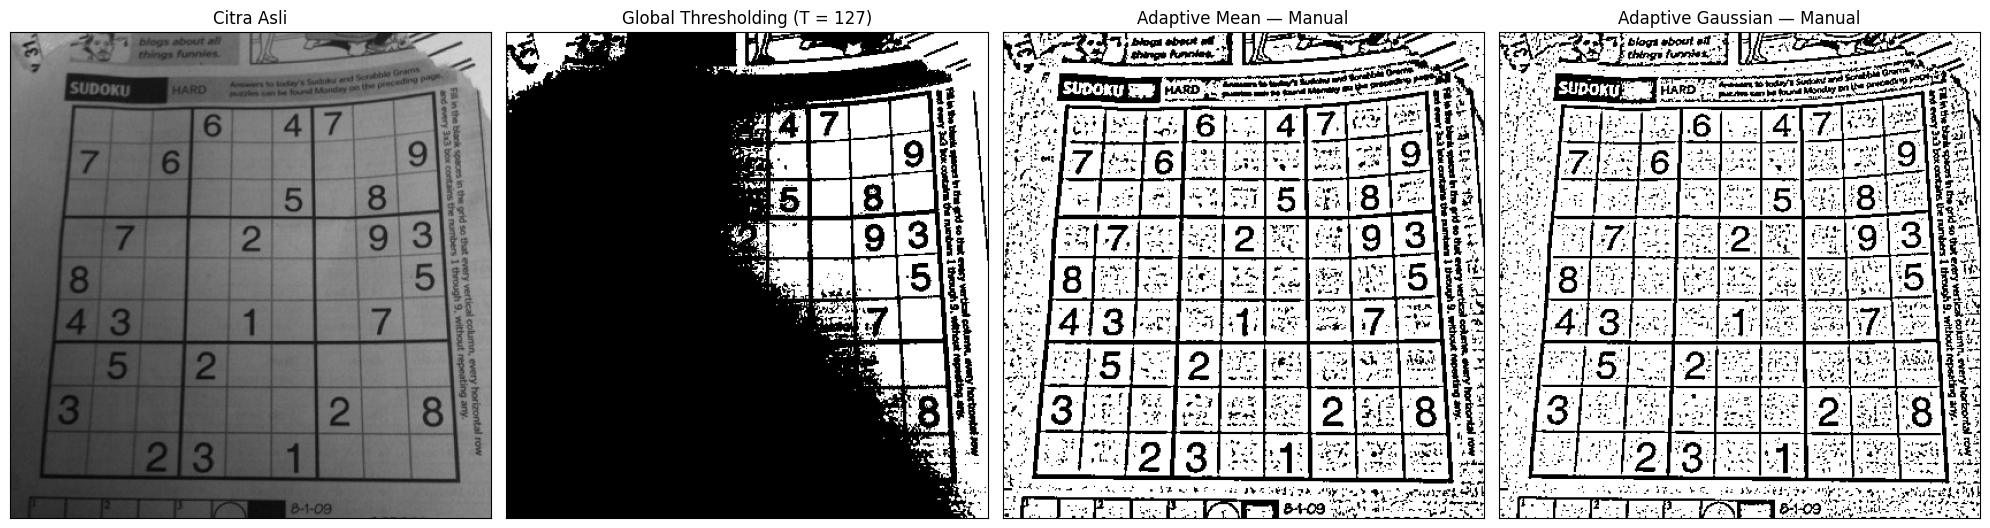

In [ ]:
gray_sudoku = cv.imread(FILE_SUDOKU, 0)

B = 11          # ukuran jendela (b x b)
C = 2           # konstanta pengurang
SIGMA = 2       # sigma Gaussian
T_GLOBAL = 127

def global_manual(src, T):
    return np.where(src > T, 255, 0).astype(np.uint8)

def rata_rata_lokal(src, b):
    # Mean b x b memakai integral image
    r = b // 2
    p = np.pad(src.astype(np.float64), r, mode='edge')
    ii = np.pad(p.cumsum(axis=0).cumsum(axis=1), ((1, 0), (1, 0)))   # integral image
    H, W = src.shape
    jumlah = (ii[b:b + H, b:b + W] - ii[0:H, b:b + W]
              - ii[b:b + H, 0:W] + ii[0:H, 0:W])
    return jumlah / (b * b)

def kernel_gaussian_1d(b, sigma):
    sumbu = np.arange(b) - b // 2
    k = np.exp(-(sumbu ** 2) / (2 * sigma ** 2))
    return k / k.sum()

def rata_rata_gaussian_lokal(src, b, sigma):
    # Rata-rata berbobot Gaussian: konvolusi horizontal, lalu vertikal (dijumlah manual)
    r = b // 2
    k = kernel_gaussian_1d(b, sigma)
    p = np.pad(src.astype(np.float64), r, mode='edge')
    H, W = src.shape
    horizontal = np.zeros((H + 2 * r, W))
    for i in range(b):
        horizontal += k[i] * p[:, i:i + W]
    hasil = np.zeros((H, W))
    for i in range(b):
        hasil += k[i] * horizontal[i:i + H, :]
    return hasil

def adaptive_manual(src, rata2_lokal, C):
    ambang_lokal = rata2_lokal - C                      # T(x,y)
    return np.where(src > ambang_lokal, 255, 0).astype(np.uint8)

th_global   = global_manual(gray_sudoku, T_GLOBAL)
th_adp_mean = adaptive_manual(gray_sudoku, rata_rata_lokal(gray_sudoku, B), C)
th_adp_gaus = adaptive_manual(gray_sudoku, rata_rata_gaussian_lokal(gray_sudoku, B, SIGMA), C)

titles = ['Citra Asli', f'Global Thresholding (T = {T_GLOBAL})',
          'Adaptive Mean — Manual', 'Adaptive Gaussian — Manual']
citra_adp = [gray_sudoku, th_global, th_adp_mean, th_adp_gaus]

plt.figure(figsize=(20, 6))
for i, im in enumerate(citra_adp):
    plt.subplot(1, 4, i + 1)
    plt.imshow(im, cmap='gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

## D1.5 Otsu Thresholding tanpa library

**A.** Otsu dibuat manual: untuk setiap kandidat `t` (1–255), hitung bobot dan rata-rata kelas background (`< t`) dan foreground (`≥ t`), lalu pilih `t` dengan **between-class variance** terbesar:

`σ²_B(t) = ω_b · ω_f · (μ_b − μ_f)²`

Kandidat yang salah satu kelasnya kosong dilewati (menghindari pembagian dengan 0).

Threshold Otsu manual  : 114 (piksel >= nilai ini menjadi putih)
Threshold Otsu library : 113.0
Hasil manual == library: True


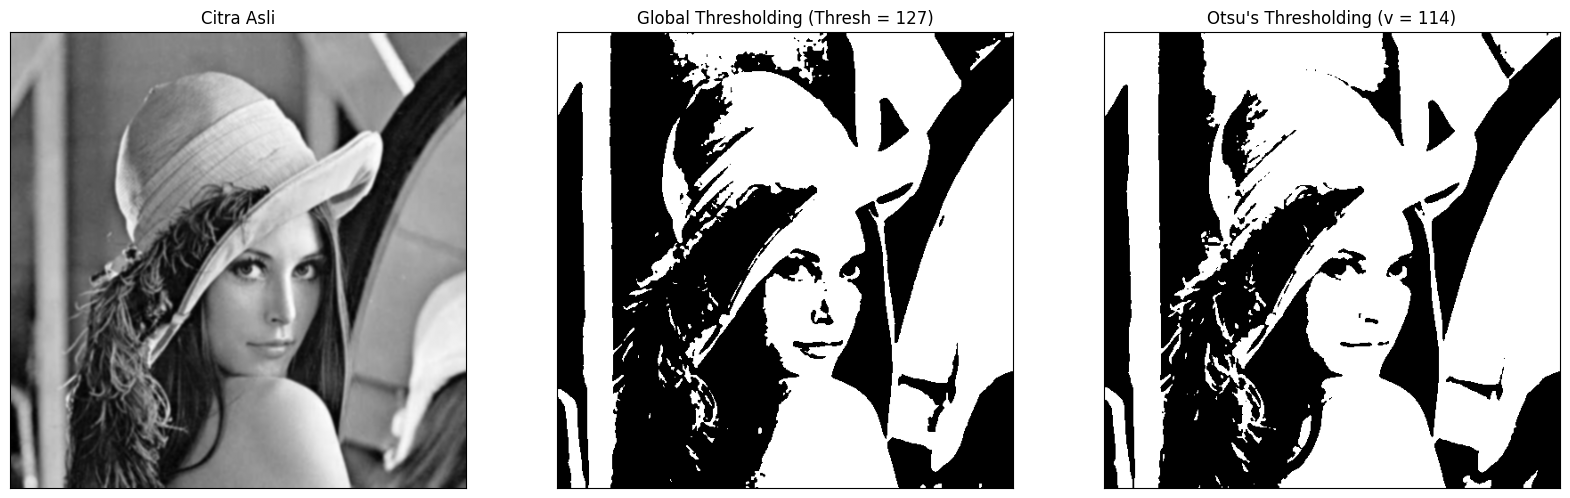

In [ ]:
def otsu_manual(gray):
    hist = np.bincount(gray.ravel(), minlength=256).astype(np.float64)
    p = hist / hist.sum()                  # probabilitas tiap level
    level = np.arange(256)
    sigma_b = np.zeros(256)                # between-class variance untuk tiap t
    best_t, best_val = 0, -1.0
    for t in range(1, 256):
        w_b = p[:t].sum()                  # bobot background (level < t)
        w_f = p[t:].sum()                  # bobot foreground (level >= t)
        if w_b == 0 or w_f == 0:
            continue
        mu_b = np.sum(level[:t] * p[:t]) / w_b
        mu_f = np.sum(level[t:] * p[t:]) / w_f
        sigma_b[t] = w_b * w_f * (mu_b - mu_f) ** 2
        if sigma_b[t] > best_val:
            best_val, best_t = sigma_b[t], t
    biner = np.where(gray >= best_t, 255, 0).astype(np.uint8)   # >= t -> putih
    return biner, best_t, sigma_b

# --- A. Citra Lena low contrast
img = cv.imread(FILE_LENA, 0)
blur = cv.GaussianBlur(img, (5, 5), 0)
thresh = 127

otsu_biner, otsu_thresh, sigma_b = otsu_manual(blur)
print('Threshold Otsu manual  :', otsu_thresh, '(piksel >= nilai ini menjadi putih)')

# Pembanding: library OpenCV (mengembalikan T, piksel > T menjadi putih, jadi T_library = T_manual - 1)
ret_lib, th_lib = cv.threshold(blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
print('Threshold Otsu library :', ret_lib)
print('Hasil manual == library:', np.array_equal(otsu_biner, th_lib))

ret, th1 = cv.threshold(blur, thresh, 255, cv.THRESH_BINARY)   # global 127 sebagai pembanding

x = "Otsu's Thresholding (v = " + str(otsu_thresh) + ")"
titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize=(20, 15))
for i in range(len(citra3)):
    plt.subplot(1, 3, i + 1), plt.imshow(citra3[i], 'gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

### Pertanyaan: mengapa Binary Thresholding (T = 127) pada Lena menghasilkan citra hitam semua?
Histogram di bawah menunjukkan sebaran intensitas citra, garis merah = T global (127), garis hitam = T Otsu.

Intensitas minimum : 0
Intensitas maksimum: 254
Piksel > 127 : 132769 dari 262144 piksel


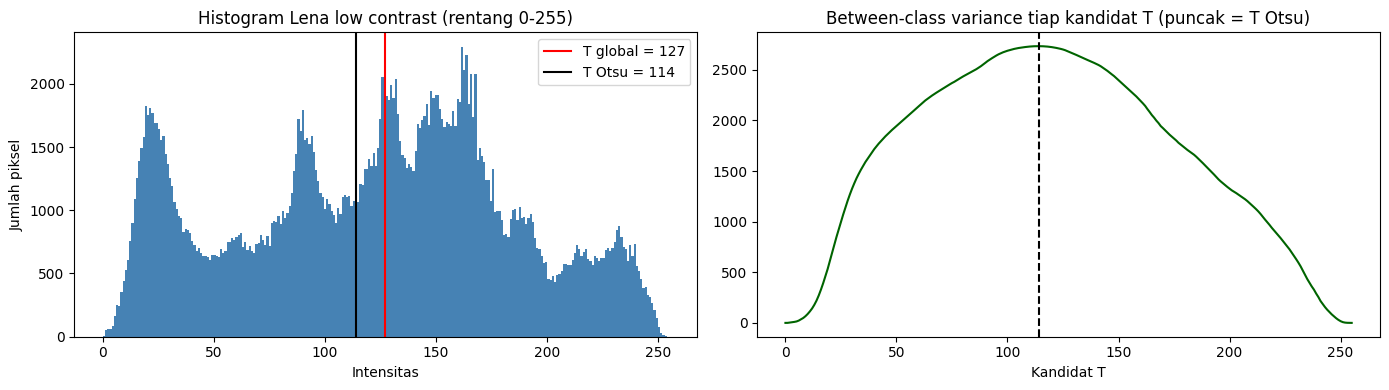

T yang masih memisahkan Lena: 0 <= T < 254


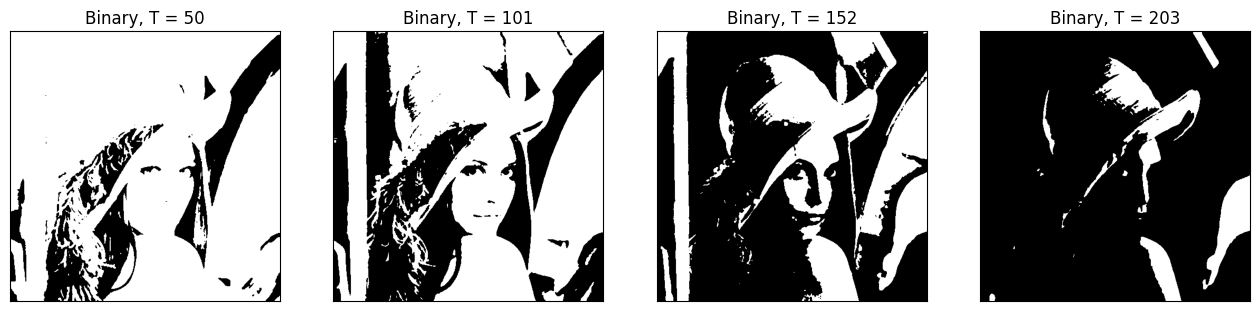

In [ ]:
print('Intensitas minimum :', blur.min())
print('Intensitas maksimum:', blur.max())
print(f'Piksel > 127 : {(blur > 127).sum()} dari {blur.size} piksel')

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].hist(blur.ravel(), bins=256, range=(0, 255), color='steelblue')
ax[0].axvline(127, color='red', label='T global = 127')
ax[0].axvline(otsu_thresh, color='black', label=f'T Otsu = {otsu_thresh}')
ax[0].set_title('Histogram Lena low contrast (rentang 0-255)')
ax[0].set_xlabel('Intensitas'), ax[0].set_ylabel('Jumlah piksel'), ax[0].legend()

ax[1].plot(sigma_b, color='darkgreen')
ax[1].axvline(otsu_thresh, color='black', linestyle='--')
ax[1].set_title('Between-class variance tiap kandidat T (puncak = T Otsu)')
ax[1].set_xlabel('Kandidat T')
plt.tight_layout(), plt.show()

# Rentang T yang masih menghasilkan dua kelas: min <= T < max
print(f'T yang masih memisahkan Lena: {blur.min()} <= T < {blur.max()}')

T_coba = np.linspace(blur.min(), blur.max(), 6).astype(int)[1:-1]
plt.figure(figsize=(16, 4))
for i, T in enumerate(T_coba):
    plt.subplot(1, len(T_coba), i + 1)
    plt.imshow(np.where(blur > T, 255, 0), cmap='gray', vmin=0, vmax=255)
    plt.title(f'Binary, T = {T}')
    plt.xticks([]), plt.yticks([])
plt.show()

**Jawaban (cek angka dengan output sel di atas):**

Citra Lena yang dipakai bersifat *low contrast*: seluruh intensitasnya hanya berada di rentang sempit sekitar **85–108** (lihat nilai minimum dan maksimum pada output). Pada histogram, semua batang berada di **sebelah kiri garis merah T = 127**. Aturan BINARY: piksel > T menjadi 255 dan piksel ≤ T menjadi 0. Karena tidak ada satu pun piksel yang lebih besar dari 127 (jumlah piksel > 127 = 0), seluruh piksel menjadi 0 sehingga citra hitam semua.

Agar Lena masih terlihat, T harus berada **di dalam rentang intensitas citra**, yaitu kira-kira **85 ≤ T < 108**. Nilai yang paling baik berada di tengah sebaran histogram, yaitu sekitar **92–93** (hasil Otsu pada citra ini), karena memisahkan dua kelompok histogram secara seimbang. T yang terlalu dekat batas (misalnya 86 atau 107) membuat hampir seluruh citra menjadi satu warna.

### B. Uji dengan citra KTP sendiri
Bandingkan global threshold biasa (T = 127) dengan Otsu manual.

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
FOLDER   = '/content/drive/MyDrive/PCVK/Images/244107020059/'
FILE_KTM = os.path.join(FOLDER, 'KTM1b.jpg')

print('Folder ada? :', os.path.exists(FOLDER))
print('File ada?   :', os.path.exists(FILE_KTM))
print('Isi folder  :', os.listdir(FOLDER) if os.path.exists(FOLDER) else '-')

Mounted at /content/drive
Folder ada? : True
File ada?   : True
Isi folder  : ['KTM1a.jpg', 'KTM1b.jpg', 'KTM1c.jpg', 'KTM1d.jpg', 'OBJ1.jpg', 'galaxy.jpg', 'noises-image.zip', 'noises', 'NIGHT1.jpg', 'lena.jpg', 'lena_lc.jpg', 'djawatan.jpg', 'mandrill.tiff', 'jungle.png', 'ktp_fulan.jpg', 'ktp_fulani.jpg', 'lily.jpg', 'sudoku-original.jpg']


In [ ]:
def otsu_manual(gray):
    # histogram 256 bin
    hist = np.bincount(gray.ravel(), minlength=256).astype(np.float64)
    prob = hist / hist.sum()

    omega = np.cumsum(prob)                      # probabilitas kumulatif kelas 0
    mu    = np.cumsum(prob * np.arange(256))     # rata-rata kumulatif
    mu_t  = mu[-1]                               # rata-rata total

    # varians antar-kelas untuk setiap kandidat threshold
    with np.errstate(divide='ignore', invalid='ignore'):
        sigma_b = (mu_t * omega - mu) ** 2 / (omega * (1 - omega))
    sigma_b = np.nan_to_num(sigma_b)

    t = int(np.argmax(sigma_b))                  # threshold optimal
    biner = np.where(gray > t, 255, 0).astype(np.uint8)
    return biner, t, hist

Threshold Otsu KTM: 130


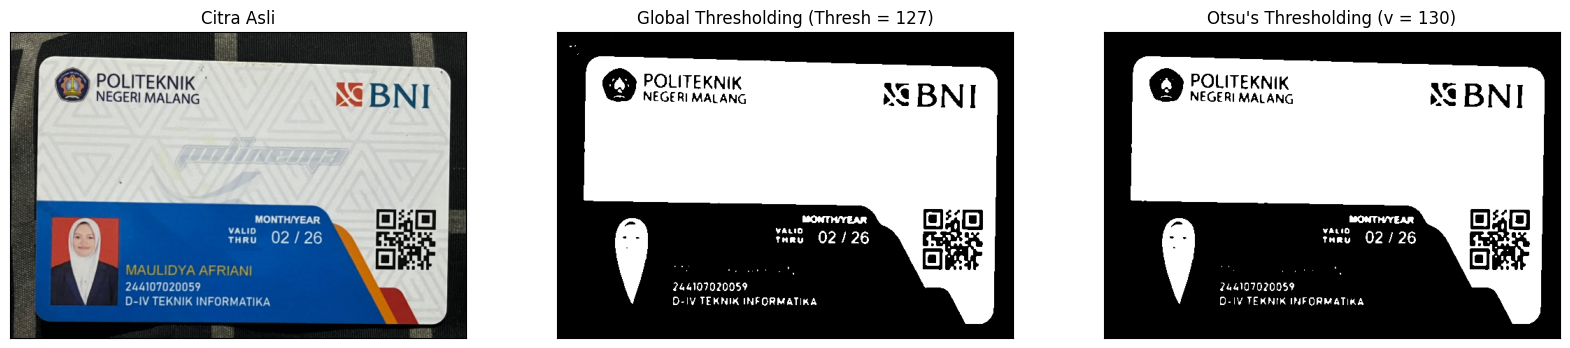

In [ ]:
ktm_bgr = cv.imread(FILE_KTM)
assert ktm_bgr is not None, f'Gagal membaca file: {FILE_KTM}'

ktm_rgb  = cv.cvtColor(ktm_bgr, cv.COLOR_BGR2RGB)
ktm_gray = cv.cvtColor(ktm_bgr, cv.COLOR_BGR2GRAY)
ktm_blur = cv.GaussianBlur(ktm_gray, (5, 5), 0)

ktm_global = np.where(ktm_blur > 127, 255, 0).astype(np.uint8)
ktm_otsu, ktm_t, _ = otsu_manual(ktm_blur)
print('Threshold Otsu KTM:', ktm_t)

plt.figure(figsize=(20, 5))
plt.subplot(1, 3, 1), plt.imshow(ktm_rgb), plt.title('Citra Asli')
plt.subplot(1, 3, 2), plt.imshow(ktm_global, 'gray', vmin=0, vmax=255), plt.title('Global Thresholding (Thresh = 127)')
plt.subplot(1, 3, 3), plt.imshow(ktm_otsu, 'gray', vmin=0, vmax=255), plt.title(f"Otsu's Thresholding (v = {ktm_t})")
for a in plt.gcf().axes:
    a.set_xticks([]), a.set_yticks([])
plt.show()

**Perbandingan (sesuaikan dengan hasil KTP-ku):** Pada KTP, latar kartu berwarna terang (biru muda) dan tulisan lebih gelap. Global threshold 127 memakai angka tetap yang tidak melihat sebaran histogram, sehingga latar yang cukup terang menjadi putih dan teks gelap menjadi hitam, tetapi bagian latar yang lebih gelap atau foto bisa ikut berubah warna secara kurang tepat. Otsu menghitung T dari histogram (sekitar 160-an pada contoh modul) sehingga pemisahan teks dan latar mengikuti kondisi citra, dan hasilnya lebih stabil jika pencahayaan KTP berbeda.

## D1.6 Segmentasi Berbasis Region pada `data.coins()`

**Ketentuan:** 3 seed (dalam koin, latar, tepi koin), T = 5, 20, 60, tampilan grid 3×3 (seed × T).

### A. Region Growing manual
- Mulai dari seed, tumbuh ke tetangga-4 (atas, bawah, kiri, kanan) memakai antrean (`deque`).
- Kriteria kesamaan: `|I(q) − μ_region| < T`, dengan `μ_region` rata-rata region yang terus diperbarui.
- Nilai awal region = rata-rata jendela 5×5 di sekitar seed (lebih tahan noise).

In [ ]:
import os, math, glob, re
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt
import pandas as pd
from collections import deque
from skimage import data, io
from skimage.segmentation import flood

(303, 384) uint8
Seed 1: dalam koin   (baris, kolom) = (36, 43) | intensitas = 159
Seed 2: latar        (baris, kolom) = (55, 73) | intensitas = 104
Seed 3: tepi koin    (baris, kolom) = (55, 22) | intensitas = 170


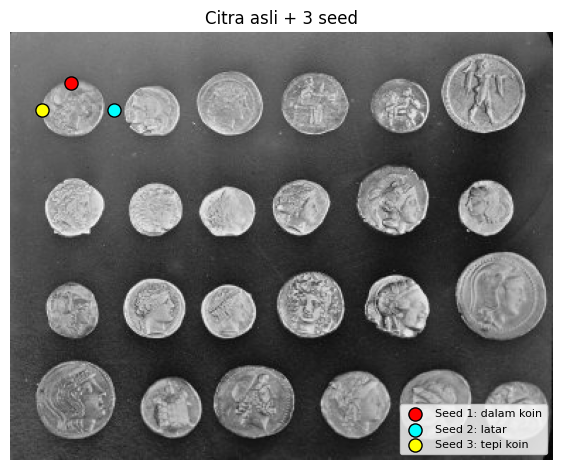

In [ ]:
coins = data.coins()          # grayscale, 303 x 384
print(coins.shape, coins.dtype)

SEEDS = {
    'Seed 1: dalam koin': (36, 43),
    'Seed 2: latar':      (55, 73),
    'Seed 3: tepi koin':  (55, 22),
}
T_LIST = [5, 20, 60]

for nama, (r, c) in SEEDS.items():
    print(f'{nama:20s} (baris, kolom) = ({r}, {c}) | intensitas = {coins[r, c]}')

rgb_seed = np.stack([coins] * 3, axis=-1)
plt.figure(figsize=(7, 6))
plt.imshow(rgb_seed)
for (nama, (r, c)), warna in zip(SEEDS.items(), ['red', 'cyan', 'yellow']):
    plt.scatter(c, r, s=90, c=warna, edgecolors='black', label=nama)
plt.legend(loc='lower right', fontsize=8)
plt.title('Citra asli + 3 seed')
plt.axis('off')
plt.show()

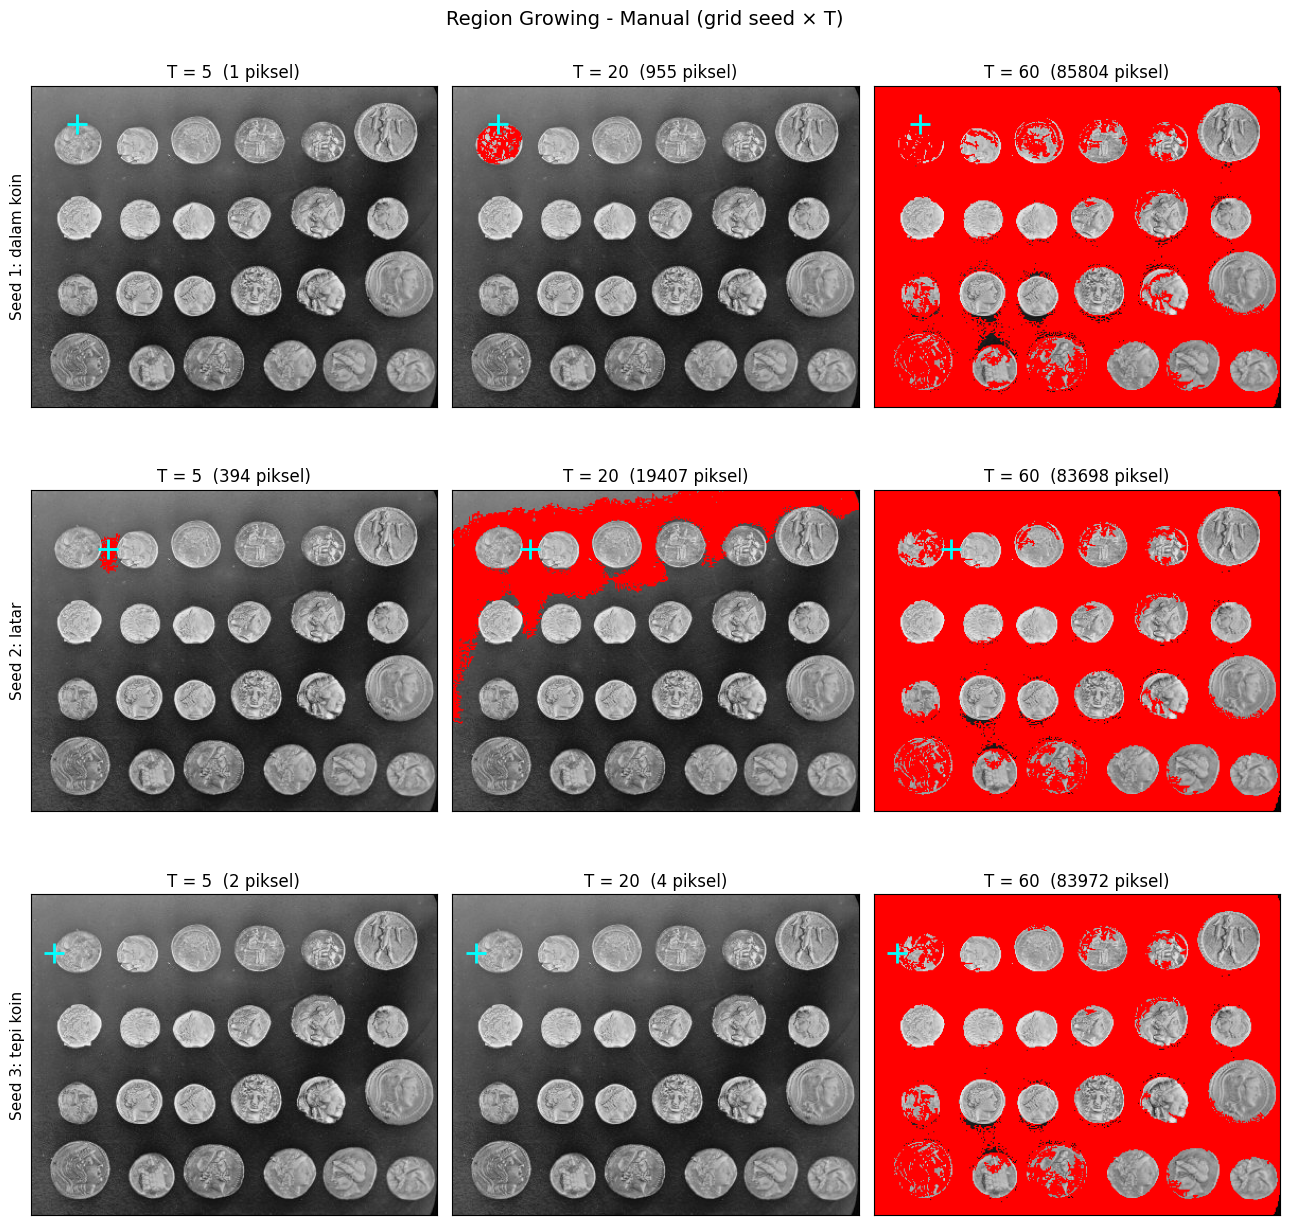

Jumlah piksel region (manual):


,T=5,T=20,T=60
Seed 1: dalam koin,1,955,85804
Seed 2: latar,394,19407,83698
Seed 3: tepi koin,2,4,83972


In [ ]:
def region_growing(gray, seed, T, connectivity=4):
    g = gray.astype(np.float64)
    H, W = g.shape
    r0, c0 = seed

    nilai_seed = g[max(0, r0 - 2):r0 + 3, max(0, c0 - 2):c0 + 3].mean()

    mask = np.zeros((H, W), dtype=bool)
    mask[r0, c0] = True
    jumlah, banyak = nilai_seed, 1

    if connectivity == 4:
        tetangga = [(-1, 0), (1, 0), (0, -1), (0, 1)]
    else:
        tetangga = [(-1, -1), (-1, 0), (-1, 1), (0, -1), (0, 1), (1, -1), (1, 0), (1, 1)]

    antrean = deque([(r0, c0)])
    while antrean:
        y, x = antrean.popleft()
        for dy, dx in tetangga:
            ny, nx = y + dy, x + dx
            if 0 <= ny < H and 0 <= nx < W and not mask[ny, nx]:
                if abs(g[ny, nx] - jumlah / banyak) < T:
                    mask[ny, nx] = True
                    jumlah += g[ny, nx]
                    banyak += 1
                    antrean.append((ny, nx))
    return mask

def grid_region(fungsi, judul_grid):
    fig, axes = plt.subplots(len(SEEDS), len(T_LIST), figsize=(13, 13))
    tabel = {}
    for i, (nama, seed) in enumerate(SEEDS.items()):
        tabel[nama] = []
        for j, T in enumerate(T_LIST):
            mask = fungsi(coins, seed, T)
            tabel[nama].append(int(mask.sum()))
            overlay = np.stack([coins] * 3, axis=-1).copy()
            overlay[mask] = [255, 0, 0]
            ax = axes[i, j]
            ax.imshow(overlay)
            ax.plot(seed[1], seed[0], marker='+', color='cyan', ms=14, mew=2)
            ax.set_title(f'T = {T}  ({mask.sum()} piksel)')
            ax.set_xticks([]), ax.set_yticks([])
            if j == 0:
                ax.set_ylabel(nama, fontsize=11)
    fig.suptitle(judul_grid, fontsize=14)
    plt.tight_layout()
    plt.show()
    return pd.DataFrame(tabel, index=[f'T={t}' for t in T_LIST]).T

hasil_manual = grid_region(region_growing, 'Region Growing - Manual (grid seed × T)')
print('Jumlah piksel region (manual):')
hasil_manual

### B. Region Growing dengan `skimage.segmentation.flood()`
`flood()` menerima piksel yang **terhubung** (connectivity=1 → 4 tetangga) dan intensitasnya berada dalam `tolerance` terhadap **intensitas seed**.

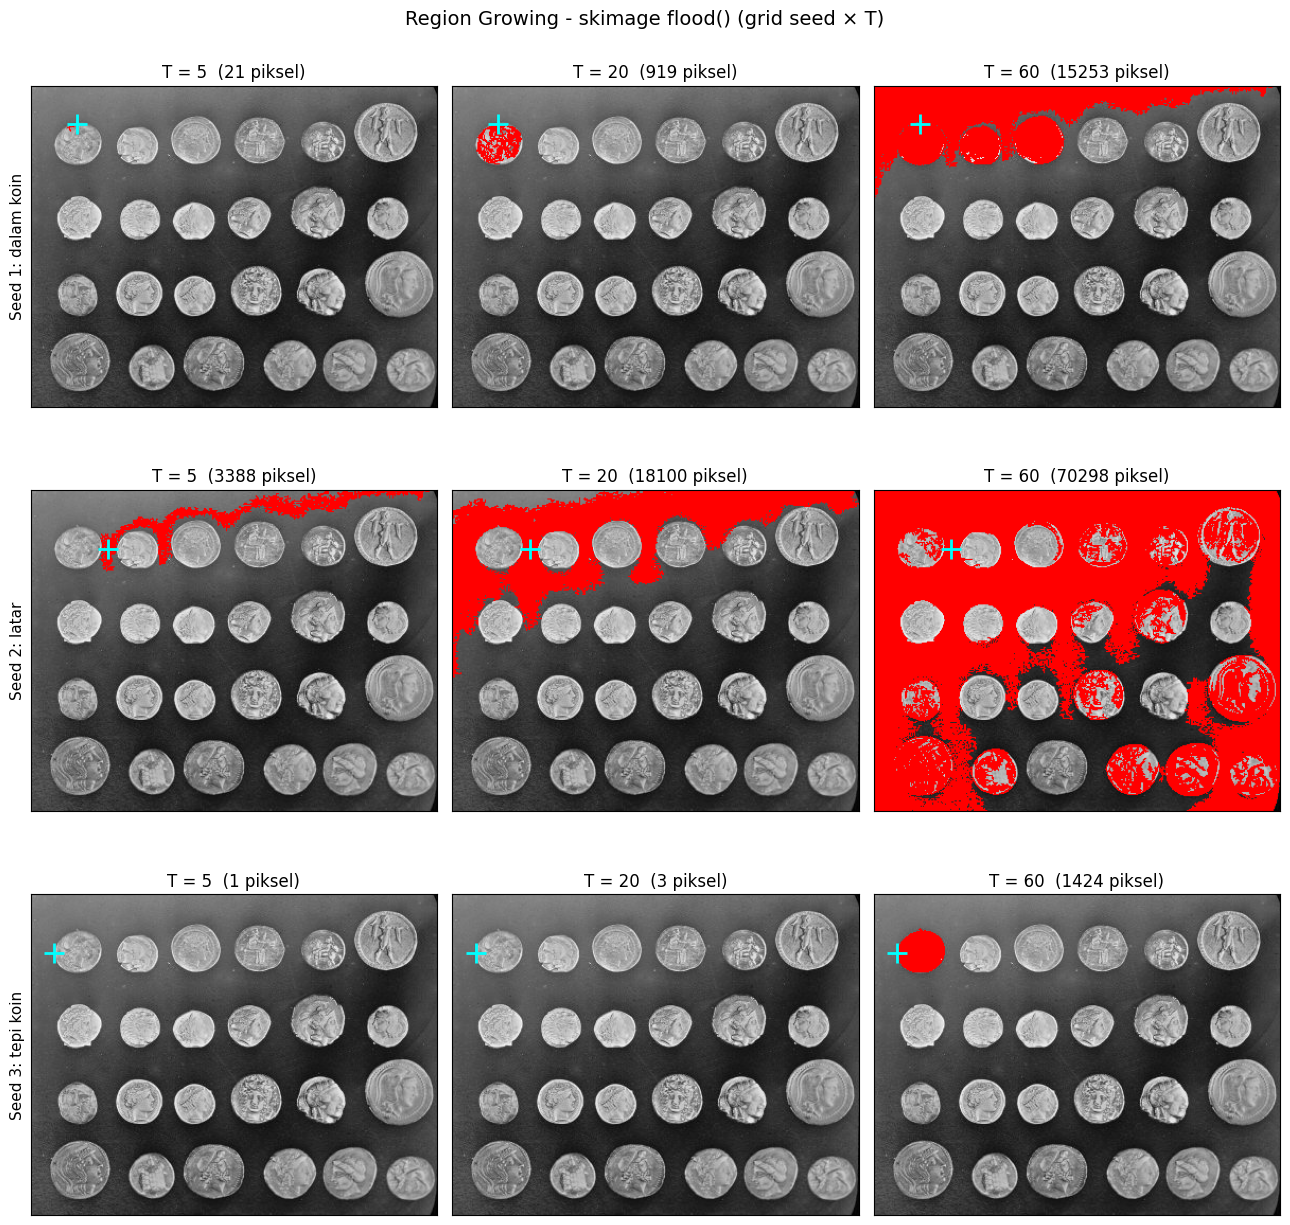

Jumlah piksel region (flood):


,T=5,T=20,T=60
Seed 1: dalam koin,21,919,15253
Seed 2: latar,3388,18100,70298
Seed 3: tepi koin,1,3,1424


In [ ]:
def region_flood(gray, seed, T):
    return flood(gray, seed_point=seed, tolerance=T, connectivity=1)   # 4 tetangga

hasil_flood = grid_region(region_flood, 'Region Growing - skimage flood() (grid seed × T)')
print('Jumlah piksel region (flood):')
hasil_flood

In [ ]:
banding = pd.concat({'Manual': hasil_manual, 'flood()': hasil_flood}, axis=1)
banding

Manual               flood()              
                      T=5   T=20   T=60     T=5   T=20   T=60
Seed 1: dalam koin      1    955  85804      21    919  15253
Seed 2: latar         394  19407  83698    3388  18100  70298
Seed 3: tepi koin       2      4  83972       1      3   1424

**Analisis singkat (cek dengan grid dan tabel di atas):**
- **Seed dalam koin:** T = 5 hanya menumbuhkan sedikit piksel (bercak kecil di sekitar seed karena tekstur koin tidak seragam), T = 20 mencakup sebagian besar permukaan koin, dan T = 60 mulai bocor ke latar atau koin di sebelahnya.
- **Seed latar:** latar relatif homogen sehingga T kecil sudah menumbuhkan area luas; pada T = 60 region ikut memasuki koin karena selisih intensitas koin dan latar masih di bawah ambang.
- **Seed tepi koin:** hasilnya paling tidak stabil karena nilai seed berada di antara intensitas koin dan latar, sehingga region mudah menyebar ke salah satu sisi.
- **Manual vs `flood()`:** `flood()` membandingkan setiap piksel dengan nilai **seed tetap**, sedangkan versi manual membandingkan dengan **rata-rata region yang terus berubah**. Karena itu versi manual cenderung bocor lebih jauh pada T besar (jumlah piksel lebih banyak).
- Kesimpulan: hasil sangat bergantung pada **posisi seed dan nilai T**. T terlalu kecil → *under-growing*, T terlalu besar → region bocor.

## D1.7 Segmentasi warna dengan K-Means: hanya warna biru (KTP)

Langkah: (1) K-Means (K = 8) pada piksel RGB, (2) ubah warna pusat tiap cluster ke HSV, (3) pilih cluster biru dengan
`np.where((H >= 85) & (H <= 130) & (S >= 25) & (V >= 40))`, (4) tampilkan hanya piksel dari cluster biru, selain itu hitam.

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,R,G,B,H,S,V,Piksel,Biru?
0,40,42,43,100,18,43,28597,-
1,199,201,200,75,3,201,43883,-
2,3,71,148,106,250,148,60069,ya
3,14,16,16,90,32,16,36629,-
4,175,73,37,8,201,175,8238,-
5,132,139,142,99,18,142,7073,-
6,84,84,78,30,18,84,13333,-
7,215,217,213,45,5,217,87754,-


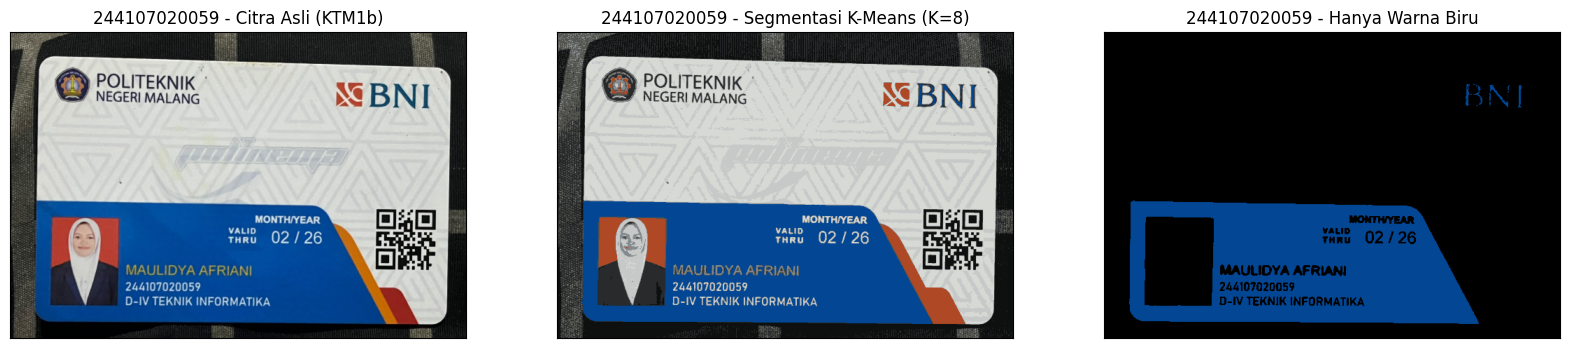

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import KMeans

NIM      = '244107020059'
BASE     = '/content/drive/MyDrive/PCVK/Images/' + NIM
FILE_KTM = BASE + '/KTM1b.jpg'

bgr_asli = cv.imread(FILE_KTM)
assert bgr_asli is not None, f'Gagal membaca file: {FILE_KTM}'
img_rgb = cv.cvtColor(bgr_asli, cv.COLOR_BGR2RGB)

MAX_LEBAR = 1000
if img_rgb.shape[1] > MAX_LEBAR:
    skala = MAX_LEBAR / img_rgb.shape[1]
    img_rgb = cv.resize(img_rgb, None, fx=skala, fy=skala, interpolation=cv.INTER_AREA)

h, w = img_rgb.shape[:2]
Z = np.float32(img_rgb.reshape(-1, 3))

K = 8
kmeans = KMeans(n_clusters=K, n_init=5, random_state=42).fit(Z)
labels  = kmeans.labels_
centers = np.uint8(kmeans.cluster_centers_)
img_kmeans = centers[labels].reshape(img_rgb.shape)

centers_hsv = cv.cvtColor(centers.reshape(1, -1, 3), cv.COLOR_RGB2HSV).reshape(-1, 3).astype(int)
H_, S_, V_ = centers_hsv[:, 0], centers_hsv[:, 1], centers_hsv[:, 2]

kelompok_biru = np.where((H_ >= 85) & (H_ <= 130) & (S_ >= 25) & (V_ >= 40))[0]

tabel_cluster = pd.DataFrame({
    'R': centers[:, 0], 'G': centers[:, 1], 'B': centers[:, 2],
    'H': H_, 'S': S_, 'V': V_,
    'Piksel': np.bincount(labels, minlength=K),
    'Biru?': ['ya' if i in kelompok_biru else '-' for i in range(K)],
})
display(tabel_cluster)

mask_biru = np.isin(labels, kelompok_biru).reshape(h, w)
hanya_biru = img_kmeans.copy()
hanya_biru[~mask_biru] = 0

plt.figure(figsize=(20, 5))
plt.subplot(1, 3, 1), plt.imshow(img_rgb),    plt.title(NIM + ' - Citra Asli (KTM1b)')
plt.subplot(1, 3, 2), plt.imshow(img_kmeans), plt.title(NIM + f' - Segmentasi K-Means (K={K})')
plt.subplot(1, 3, 3), plt.imshow(hanya_biru), plt.title(NIM + ' - Hanya Warna Biru')
for a in plt.gcf().axes:
    a.set_xticks([]), a.set_yticks([])
plt.show()



Persentase 21%: 60.069 dibagi total piksel semua cluster (285.576).
Alasan penolakan: syarat kode adalah (H>=85)&(H<=130)&(S>=25)&(V>=40). Cluster 0 dan 5 gagal di S, cluster 3 gagal di V.
Warna cluster lain: dibaca dari nilai RGB di tabel (misalnya cluster 4 = 175, 73, 37 berarti oranye kecokelatan).

---
# D2. Tugas Kelompok — Konversi gambar KTP menjadi teks (OCR)


In [ ]:
!apt-get -qq update
!apt-get -qq install tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
{'Berwarna': (806, 1200, 3), 'Otsu': (806, 1200), 'Adaptive': (806, 1200)}


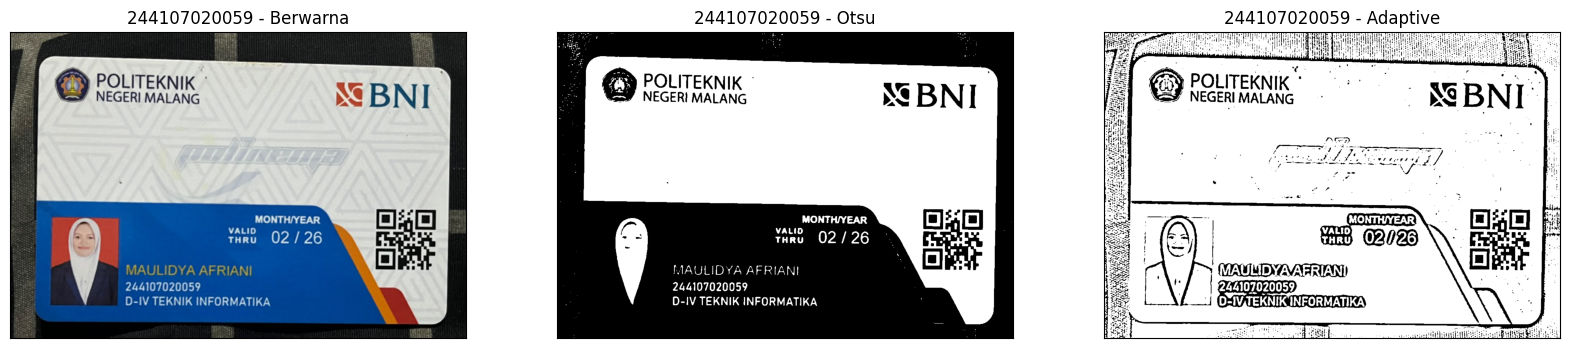

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import re, difflib
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt
import pandas as pd
import pytesseract
from pytesseract import Output

NIM      = '244107020059'
BASE     = '/content/drive/MyDrive/PCVK/Images/' + NIM
FILE_KTM = BASE + '/KTM1b.jpg'

# pengaturan yang sama untuk ketiga citra
LANG     = 'ind'
PSM      = 6
CONFIG   = f'--psm {PSM}'
CONF_MIN = 60
LEBAR    = 1200

bgr = cv.imread(FILE_KTM)
assert bgr is not None, f'Gagal membaca file: {FILE_KTM}'
skala = LEBAR / bgr.shape[1]
bgr = cv.resize(bgr, (LEBAR, int(bgr.shape[0] * skala)), interpolation=cv.INTER_CUBIC)

rgb_ocr  = cv.cvtColor(bgr, cv.COLOR_BGR2RGB)
gray_ocr = cv.cvtColor(bgr, cv.COLOR_BGR2GRAY)
_, img_otsu_ocr = cv.threshold(gray_ocr, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
img_adapt_ocr   = cv.adaptiveThreshold(gray_ocr, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C,
                                       cv.THRESH_BINARY, 31, 10)

citra_ocr = {'Berwarna': rgb_ocr, 'Otsu': img_otsu_ocr, 'Adaptive': img_adapt_ocr}
print({k: v.shape for k, v in citra_ocr.items()})

plt.figure(figsize=(20, 5))
for i, (nama, im) in enumerate(citra_ocr.items()):
    plt.subplot(1, 3, i + 1)
    plt.imshow(im, cmap=None if im.ndim == 3 else 'gray')
    plt.title(NIM + ' - ' + nama), plt.xticks([]), plt.yticks([])
plt.show()

### Langkah 2 — Pembacaan teks dengan `image_to_string()`

In [ ]:
hasil_ocr = {}
for nama, im in citra_ocr.items():
    teks = pytesseract.image_to_string(im, lang=LANG, config=CONFIG)
    dt   = pytesseract.image_to_data(im, lang=LANG, config=CONFIG, output_type=Output.DICT)
    hasil_ocr[nama] = {'teks': teks, 'data': dt}
    print('=' * 10, nama.upper(), '=' * 10)
    print(teks)

========== BERWARNA ==========
TN | x |
PI (@P2TEKnIK Xe BNI
| e Oo,
fan v 02 EA
“ e |
: MAULIDYA AFRIANI

========== OTSU ==========
BI GP POLITEKNIK - |
Pa @ NEGERI MALANG AC BNI
MONTH/YEAR OtD|
MUD 92/26" EA
MAULIDYA AFRIANI | js) ,
244107020059
. D-IV TEKNIK INFORMATIKA '

========== ADAPTIVE ==========
AM MAA Ne LN Madaa
Pe An An An fa MN Ro Kn en MEN
Tp MA Mn a
3 . . n ta . Fani db at an atik
i POLITEKNIK 2 . La
lal SS NeGERIMALANG BNI
Mena : MA ban Saba De asn ah ui
AA - . Hana . 6
STA RAN CSO F
TG | A VALID " Hat
Tai IA Tr 2S NE eh
Ss :
. IP AIA UNIDYAYAKRIANI BRA
Ia Oy MN $22:2107020053 1

ha BESI K DIV, TEKNIK INFORMATIKA 1.
ee ea ag tin eye BEN Teen Ba al



### Langkah 3 — Area teks yang dikenali (kotak hijau, confidence > 60)

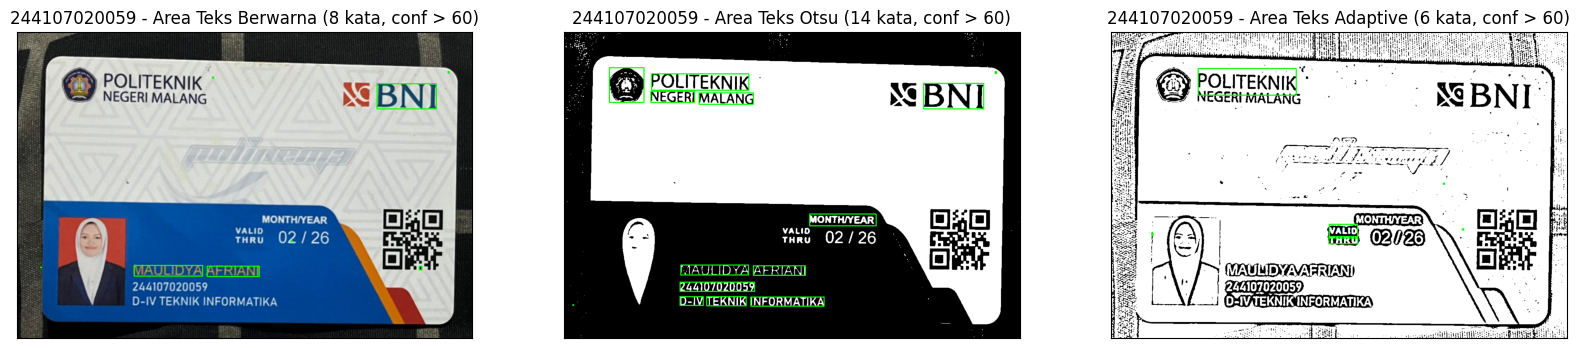

In [ ]:
assert 'hasil_ocr' in globals(), 'Jalankan Langkah 2 (image_to_string) dulu.'

def gambar_kotak(im, dt, conf_min=CONF_MIN):
    vis = cv.cvtColor(im, cv.COLOR_GRAY2RGB) if im.ndim == 2 else im.copy()
    jumlah = 0
    for i in range(len(dt['text'])):
        kata = dt['text'][i].strip()
        try:
            conf = float(dt['conf'][i])
        except ValueError:
            conf = -1
        if kata and conf > conf_min:
            x, y, w_, h_ = dt['left'][i], dt['top'][i], dt['width'][i], dt['height'][i]
            cv.rectangle(vis, (x, y), (x + w_, y + h_), (0, 255, 0), 2)
            jumlah += 1
    return vis, jumlah

plt.figure(figsize=(20, 6))
for i, (nama, im) in enumerate(citra_ocr.items()):
    vis, n = gambar_kotak(im, hasil_ocr[nama]['data'])
    plt.subplot(1, 3, i + 1)
    plt.imshow(vis)
    plt.title(f'{NIM} - Area Teks {nama} ({n} kata, conf > {CONF_MIN})')
    plt.xticks([]), plt.yticks([])
plt.show()

### Langkah 4–5 — Tabel perbandingan 10 kata dan persentase kecocokan
**Isi `GROUND_TRUTH` dengan 10 kata/angka yang terlihat jelas di KTP-mu** (tulis persis seperti di gambar, tanpa tanda baca di ujung kata). Contoh di bawah mengikuti KTP contoh pada modul.

Aturan penilaian: cocok jika seluruh huruf/angka sama dengan acuan; huruf besar/kecil dan spasi/tanda baca di awal–akhir kata diabaikan. Kata yang tidak terbaca dihitung tidak cocok.

In [ ]:
assert 'hasil_ocr' in globals(), 'Jalankan Langkah 2 (image_to_string) dulu.'

# >>> cocokkan dengan tulisan di KTM-mu (dari gambar, bukan dari hasil OCR) <<<
GROUND_TRUTH = ['POLITEKNIK', 'NEGERI', 'MALANG', 'MAULIDYA', 'AFRIANI',
                '244107020059', 'D-IV', 'TEKNIK', 'INFORMATIKA', 'BNI']

def bersih(s):
    return re.sub(r'^[\W_]+|[\W_]+$', '', s.strip()).lower()

def daftar_kata(teks):
    kata = [bersih(t) for t in re.split(r'\s+', teks)]
    return [k for k in kata if k]

baris, cocok = [], {n: 0 for n in citra_ocr}
salah = {n: [] for n in citra_ocr}

for no, acuan in enumerate(GROUND_TRUTH, 1):
    baris_tabel = {'No': no, 'Teks sebenarnya': acuan}
    for nama in citra_ocr:
        kata_ocr = daftar_kata(hasil_ocr[nama]['teks'])
        if bersih(acuan) in kata_ocr:
            tampil_kata = acuan
            cocok[nama] += 1
        else:
            mirip = difflib.get_close_matches(bersih(acuan), kata_ocr, n=1, cutoff=0.4)
            tampil_kata = mirip[0] if mirip else '(tidak terbaca)'
            salah[nama].append((acuan, tampil_kata))
        baris_tabel[f'OCR {nama}'] = tampil_kata
    baris.append(baris_tabel)

tabel_banding = pd.DataFrame(baris)
display(tabel_banding)

def rata_conf(dt):
    nilai = []
    for t, c in zip(dt['text'], dt['conf']):
        try:
            c = float(c)
        except ValueError:
            continue
        if t.strip() and c >= 0:
            nilai.append(c)
    return float(np.mean(nilai)) if nilai else 0.0

ringkasan = pd.DataFrame({
    'Citra masukan OCR': ['Berwarna asli', 'Segmentasi Otsu', 'Segmentasi Adaptive'],
    'Item terbaca tepat': [cocok[n] for n in citra_ocr],
    'Kecocokan (%)': [cocok[n] / len(GROUND_TRUTH) * 100 for n in citra_ocr],
    'Rata-rata confidence': [round(rata_conf(hasil_ocr[n]['data']), 2) for n in citra_ocr],
})
display(ringkasan)

,No,Teks sebenarnya,OCR Berwarna,OCR Otsu,OCR Adaptive
0,1,POLITEKNIK,p2teknik,POLITEKNIK,POLITEKNIK
1,2,NEGERI,bni,NEGERI,negerimalang
2,3,MALANG,maulidya,MALANG,negerimalang
3,4,MAULIDYA,MAULIDYA,MAULIDYA,valid
4,5,AFRIANI,AFRIANI,AFRIANI,fani
5,6,244107020059,(tidak terbaca),244107020059,22:2107020053
6,7,D-IV,v,D-IV,div
7,8,TEKNIK,p2teknik,TEKNIK,TEKNIK
8,9,INFORMATIKA,maulidya,INFORMATIKA,INFORMATIKA
9,10,BNI,BNI,BNI,BNI


,Citra masukan OCR,Item terbaca tepat,Kecocokan (%),Rata-rata confidence
0,Berwarna asli,3,30.0,45.10
1,Segmentasi Otsu,10,100.0,60.22
2,Segmentasi Adaptive,4,40.0,21.65


### Pertanyaan analisis
Sel berikut menampilkan fakta dari hasil percobaan di atas sebagai bahan jawaban (Q1, Q2, Q3, Q5).

In [ ]:
assert 'ringkasan' in globals(), 'Jalankan Langkah 4-5 dulu.'

nama_tampil = dict(zip(citra_ocr, ringkasan['Citra masukan OCR']))
r = ringkasan.set_index('Citra masukan OCR')

maks = r['Kecocokan (%)'].max()
daftar_terbaik = list(r.index[r['Kecocokan (%)'] == maks])
print('Q1. Pembacaan paling tepat:', ', '.join(daftar_terbaik), '(seri)' if len(daftar_terbaik) > 1 else '')
print(r[['Item terbaca tepat', 'Kecocokan (%)']].to_string(), '\n')

print('Q2. Contoh kesalahan pembacaan (acuan -> hasil OCR):')
for nama in citra_ocr:
    for acuan, hasil in salah[nama][:3]:
        print(f'   [{nama_tampil[nama]}] {acuan}  ->  {hasil}')
print()

asli = r.loc['Berwarna asli', 'Kecocokan (%)']
print('Q3. Dibanding citra berwarna asli:')
for n in ['Segmentasi Otsu', 'Segmentasi Adaptive']:
    v = r.loc[n, 'Kecocokan (%)']
    arah = 'meningkat' if v > asli else ('menurun' if v < asli else 'sama')
    print(f'   {n}: {v:.0f}% vs {asli:.0f}% -> {arah}')
print()

conf_tinggi = r['Rata-rata confidence'].idxmax()
print('Q5. Confidence tertinggi:', conf_tinggi, '| Kecocokan tertinggi:', ', '.join(daftar_terbaik))
print('    Sama?', conf_tinggi in daftar_terbaik)

Q1. Pembacaan paling tepat: Segmentasi Otsu 
                     Item terbaca tepat  Kecocokan (%)
Citra masukan OCR                                     
Berwarna asli                         3           30.0
Segmentasi Otsu                      10          100.0
Segmentasi Adaptive                   4           40.0 

Q2. Contoh kesalahan pembacaan (acuan -> hasil OCR):
   [Berwarna asli] POLITEKNIK  ->  p2teknik
   [Berwarna asli] NEGERI  ->  bni
   [Berwarna asli] MALANG  ->  maulidya
   [Segmentasi Adaptive] NEGERI  ->  negerimalang
   [Segmentasi Adaptive] MALANG  ->  negerimalang
   [Segmentasi Adaptive] MAULIDYA  ->  valid

Q3. Dibanding citra berwarna asli:
   Segmentasi Otsu: 100% vs 30% -> meningkat
   Segmentasi Adaptive: 40% vs 30% -> meningkat

Q5. Confidence tertinggi: Segmentasi Otsu | Kecocokan tertinggi: Segmentasi Otsu
    Sama? True


1. Citra yang pembacaannya paling tepat
   Citra ___ (kemungkinan Segmentasi Otsu), dengan ___ dari 10 item terbaca tepat
   (kecocokan ___%). Pembandingnya: berwarna asli ___%, Adaptive ___%.

2. Contoh kesalahan pembacaan (ambil dari output Q2)
   - NIM 244107020059 terbaca "$22:2107020053" pada citra Adaptive (angka tertukar/salah).
   - Nama MAULIDYA AFRIANI terbaca "UNIDYAYAKRIANI" pada citra Adaptive (huruf hilang/berubah).
   - ___ terbaca ___ / tidak terbaca sama sekali pada citra berwarna.

3. Apakah segmentasi selalu meningkatkan hasil OCR?
   Tidak selalu. Dibanding citra berwarna (___%), Otsu ___ (___%) tetapi Adaptive ___
   (___%). Thresholding menghilangkan latar berpola dan menaikkan kontras sehingga
   teks lebih jelas (Otsu). Namun Adaptive memakai ambang lokal, sehingga pola latar,
   logo, dan hologram ikut menjadi bintik hitam yang dibaca sebagai huruf, dan huruf
   tipis terputus. Hasilnya bisa lebih buruk daripada citra asli.

4. Pengaruh warna dan pola latar KTM
   Latar KTM berwarna dengan logo, hologram, dan pola mengurangi kontras antara huruf
   dan latar, sehingga pada citra berwarna hampir semua teks gagal terbaca (hanya
   nama yang terbaca). Segmentasi Otsu mengubah latar menjadi putih polos sehingga
   teks lebih mudah dipisahkan. Namun foto dan elemen berwarna ikut menjadi blok hitam,
   dan pada Adaptive muncul banyak noise di area berpola (lihat kotak hijau pada
   Langkah 3: jumlah kata ___ untuk berwarna, ___ untuk Otsu, ___ untuk Adaptive).

5. Apakah confidence tertinggi = kecocokan tertinggi?
   Confidence tertinggi: ___ (___), kecocokan tertinggi: ___. Keduanya (sama / tidak
   sama). Confidence hanyalah keyakinan mesin terhadap kata yang ia baca, bukan
   kebenarannya terhadap teks asli. Sebuah metode bisa punya confidence rata-rata
   tinggi karena hanya membaca sedikit kata yang mudah, sementara banyak kata lain
   tidak terbaca. Karena itu confidence tidak bisa dipakai sebagai pengganti akurasi.